# 08 - PyTorch with Lightning Flash

**Lightning Flash** was a high-level "tasks" library from the PyTorch Lightning team. You pick a task (here `TabularRegressor`) and a **backbone**, and Flash builds the data pipeline, the model and the training loop. For tabular data the backbones come from the *PyTorch Tabular* library. We use `category_embedding`, a plain MLP, so that it's different from the TabNet model in notebook 07.

**Important:** Flash was archived by Lightning AI in 2023. Its last version (0.8.2) needs `pytorch-lightning < 2.0`, so it can't be installed together with the newer PyTorch used by fastai. This notebook runs in a **separate environment** (`.venv-flash`, Python 3.10, kernel "flash-env") with pinned versions from `requirements-flash.txt`. Two fixes were needed:
- `setuptools<81`, because newer setuptools removed `pkg_resources`, which pytorch-lightning 1.9 imports
- `requests`, which Flash imports but doesn't list as a dependency

The data, the split, the scaling and the metrics come from the same `src` code as every other notebook, so the comparison stays fair.

Flash's `TabularRegressionData` accepts only **one target column**, so one model is trained per target (1M, 5Y, 30Y).

**Bug found while building this notebook:** Flash fills missing values and normalises the DataFrames you pass it **in place** (`flash/tabular/classification/utils.py`, functions `_impute` and `_normalize`). In the first version of this notebook the same DataFrames were reused for several targets and seeds. They were normalised again and again, so some models were trained or evaluated on wrongly scaled data and gave forecasts that were off by tens of percentage points. Passing a `.copy()` of every DataFrame fixed it. Since Flash is archived, this bug will never be fixed upstream.

In [1]:
import sys
import time
import logging
import warnings
sys.path.append("..")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import pytorch_lightning as pl
import flash
from flash.tabular import TabularRegressionData, TabularRegressor

from src import config, features, evaluate, plots

# hide the training log messages (has to be done after the import,
# because pytorch-lightning sets its own log level when it's imported)
for name in ["pytorch_lightning", "lightning_fabric", "flash"]:
    logging.getLogger(name).setLevel(logging.ERROR)

plots.setup()
pd.set_option("display.precision", 4)
print("Python", sys.version.split()[0], "| torch", torch.__version__,
      "| pytorch-lightning", pl.__version__, "| flash", flash.__version__)
print("Backbones:", TabularRegressor.available_backbones())
df = features.load_dataset()

Python 3.10.20 | torch 1.13.1 | pytorch-lightning 1.9.5 | flash 0.8.2
Backbones: ['autoint', 'category_embedding', 'fttransformer', 'gate', 'node', 'tabnet', 'tabtransformer']


## 1. Model

In [2]:
def train_flash(train_df, val_df, feature_cols, target, lr, epochs, seed=config.SEED):
    pl.seed_everything(seed, workers=True)
    # .copy() is important: Flash normalises the DataFrames it is given *in place*
    datamodule = TabularRegressionData.from_data_frame(
        numerical_fields=feature_cols, target_field=target,
        train_data_frame=train_df.copy(), val_data_frame=val_df.copy(), batch_size=64)
    model = TabularRegressor.from_data(datamodule, backbone="category_embedding", learning_rate=lr)
    trainer = flash.Trainer(max_epochs=epochs, accelerator="cpu", logger=False, enable_progress_bar=False,
                            enable_model_summary=False, enable_checkpointing=False)
    trainer.fit(model, datamodule=datamodule)
    return model, trainer, datamodule.parameters


def predict_flash(model, trainer, parameters, X):
    # new data must be prepared with the normalisation parameters of the training data
    datamodule = TabularRegressionData.from_data_frame(
        numerical_fields=list(X.columns), predict_data_frame=X.copy(), parameters=parameters, batch_size=256)
    batches = trainer.predict(model, datamodule=datamodule)
    return np.concatenate([np.ravel(b) for b in batches])


def make_frames(data, scaled):
    """DataFrames with the raw inputs and the standardised targets (one column per target)."""
    frames = {}
    for part in ["train", "val"]:
        frame = data[part]["X"].copy()
        frame[config.TARGETS] = scaled[part][1]
        frames[part] = frame
    return frames


def train_and_predict(data, scaled, unscale_y, mode, X_parts, lr, epochs, seed=config.SEED):
    """Train one model per target and return level predictions for each part in X_parts."""
    frames = make_frames(data, scaled)
    cols = list(data["train"]["X"].columns)
    models = {t: train_flash(frames["train"], frames["val"], cols, t, lr, epochs, seed) for t in config.TARGETS}
    out = {}
    for part in X_parts:
        raw = np.column_stack([predict_flash(*models[t], data[part]["X"]) for t in config.TARGETS])
        out[part] = evaluate.to_level(unscale_y(raw), data[part]["today"], mode)
    return out, models

## 2. Tuning on the validation set (seed 42)

In [3]:
configs = [{"lr": lr, "epochs": epochs} for lr in [1e-3, 1e-2] for epochs in [10, 30]]

best_config, tuning_rows = {}, []
for exp in config.EXPERIMENTS:
    data, mode = features.get_experiment(df, exp)
    scaled, _, unscale_y = features.scale(data)
    for cfg in configs:
        preds, _ = train_and_predict(data, scaled, unscale_y, mode, ["val"], **cfg)
        tuning_rows.append({"experiment": exp, **cfg,
                            "val RMSE (avg)": evaluate.average_rmse(data["val"]["future"], preds["val"])})
    rows = [r for r in tuning_rows if r["experiment"] == exp]
    best = min(rows, key=lambda r: r["val RMSE (avg)"])
    best_config[exp] = {k: best[k] for k in ["lr", "epochs"]}
pd.DataFrame(tuning_rows)

,experiment,lr,epochs,val RMSE (avg)
0,A,0.001,10,0.5737
1,A,0.001,30,0.5828
2,A,0.010,10,0.6240
3,A,0.010,30,0.6726
4,B,0.001,10,0.2453
5,B,0.001,30,0.2349
6,B,0.010,10,0.2733
7,B,0.010,30,0.2617
8,C,0.001,10,0.1741
9,C,0.001,30,0.1823


In [4]:
pd.DataFrame(best_config).T

,lr,epochs
A,0.001,10.0
B,0.001,30.0
C,0.010,10.0


## 3. Final models: 3 seeds per experiment

In [5]:
all_metrics, times = [], []
for exp in config.EXPERIMENTS:
    data, mode = features.get_experiment(df, exp)
    scaled, _, unscale_y = features.scale(data)
    for seed in config.SEEDS:
        start = time.time()
        preds, models = train_and_predict(data, scaled, unscale_y, mode, ["test"], seed=seed, **best_config[exp])
        if exp == "C":
            times.append(time.time() - start)
        evaluate.save_predictions("Flash", exp, seed, data["test"], preds["test"])
        m = evaluate.evaluate(data["test"]["future"], preds["test"], data["test"]["today"])
        all_metrics.append(m.assign(experiment=exp, seed=seed).reset_index())
        if exp == "C" and seed == config.SEED:
            models_c, unscale_c = models, unscale_y

metrics = pd.concat(all_metrics)
summary = metrics.groupby(["experiment", "target"])[["RMSE", "MAE", "R2", "R2_change", "skill_vs_naive", "direction_acc"]]
order = ["1M", "5Y", "30Y"]
summary.mean().reindex(order, level=1).round(4)

RMSE     MAE      R2  R2_change  skill_vs_naive  \
experiment target                                                      
A          1M      0.6486  0.5665  0.0170   -21.3420         -3.4170   
           5Y      0.6583  0.5937 -4.0933   -30.9561         -3.7735   
           30Y     0.5427  0.4640 -0.7507   -25.0337         -3.8858   
B          1M      0.2463  0.2149  0.8761    -1.8150         -0.6774   
           5Y      0.3926  0.3653 -0.2996    -7.1538         -1.8469   
           30Y     0.3908  0.3717  0.1596   -11.4980         -2.5181   
C          1M      0.1750  0.0742  0.9374    -0.4238         -0.1917   
           5Y      0.1452  0.1109  0.8229    -0.1112         -0.0527   
           30Y     0.1220  0.0958  0.9182    -0.2167         -0.0986   

                   direction_acc  
experiment target                 
A          1M             0.5501  
           5Y             0.5456  
           30Y            0.4744  
B          1M             0.4804  
           5Y             0.5433  
           30Y            0.5533  
C          1M             0.5201  
           5Y             0.4856  
           30Y            0.4770

In [6]:
summary.std()[["RMSE", "skill_vs_naive"]].reindex(order, level=1).round(4)

RMSE  skill_vs_naive
experiment target                        
A          1M      0.3026          2.0605
           5Y      0.5094          3.6937
           30Y     0.1908          1.7182
B          1M      0.0058          0.0398
           5Y      0.0293          0.2123
           30Y     0.0226          0.2036
C          1M      0.0109          0.0744
           5Y      0.0034          0.0246
           30Y     0.0033          0.0296

In [7]:
evaluate.save_run_info("Flash", {"train_seconds": float(np.mean(times)),
                                 "lines_of_code": evaluate.count_lines(train_flash) + evaluate.count_lines(predict_flash),
                                 "hyperparameters": 4,
                                 "tuning_combinations": len(configs)})

**Observations**
- After the in-place bug was fixed, Flash behaves like the other neural networks. **Experiment A** (level) fails: skill between −3.4 and −3.9.
- **Experiment B** is much worse for Flash than for Keras, fastai or TabNet: skill −0.68 (1M), −1.85 (5Y) and −2.52 (30Y). Its MLP backbone seems to extrapolate badly when the raw yield levels are inputs and the test yields are higher than anything in training. The results also vary a lot between seeds (standard deviation about 0.2).
- **Experiment C** is Flash's best: −0.19 (1M), −0.05 (5Y) and −0.10 (30Y). That's close to Keras and fastai, but still worse than naive.
- Validation picked a learning rate of 0.01 and 10 epochs for experiment C.
- Even with one model per target, training is fast: about 3 seconds for one run of experiment C.
- Direction accuracy is 48-52%.

## 4. Permutation feature importance (experiment C)

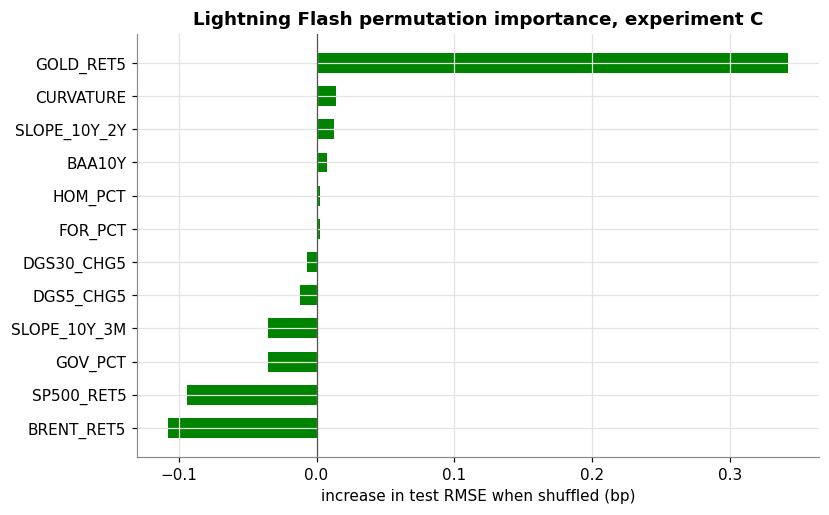

In [8]:
data_c, _ = features.get_experiment(df, "C")

def predict_level(X):
    raw = np.column_stack([predict_flash(*models_c[t], X) for t in config.TARGETS])
    return evaluate.to_level(unscale_c(raw), data_c["test"]["today"], "change")

importance = evaluate.permutation_importance(predict_level, data_c["test"]["X"], data_c["test"]["future"], n_repeats=3)
evaluate.save_importance("Flash", importance, "permutation_rmse_increase")

fig, ax = plt.subplots(figsize=(8, 5))
top = importance.head(12).iloc[::-1] * 100
ax.barh(top.index, top.values, color=plots.MODEL_COLORS["Flash"], height=0.6)
ax.axvline(0, color="#52514e", linewidth=0.8)
ax.set_xlabel("increase in test RMSE when shuffled (bp)")
ax.set_title("Lightning Flash permutation importance, experiment C")
plots.save(fig, "08_flash_importance")
plt.show()

**Observations**
- Shuffling the gold return hurts the most (+0.34 bp of RMSE). Every other feature changes the RMSE by 0.02 bp or less, and several are slightly negative (shuffling them made no difference, or even helped).
- So the Flash model relies on very few inputs, and only weakly. Its top feature is different from the other models, which mostly rely on the curve slope.
- When every network ends up close to the naive forecast, which weak feature each one happens to pick up is partly chance. This is another sign that most of the "signal" in one-week yield changes is noise.